In [5]:
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from PIL import Image

from Task_1.classes import MnistClassifier

%matplotlib inline

--- Evaluating MNIST Models ---


c:\Users\Hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Algorithm: RF   | Test Accuracy: 0.9704


c:\Users\Hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Algorithm: NN   | Test Accuracy: 0.9755
Algorithm: CNN  | Test Accuracy: 0.9840


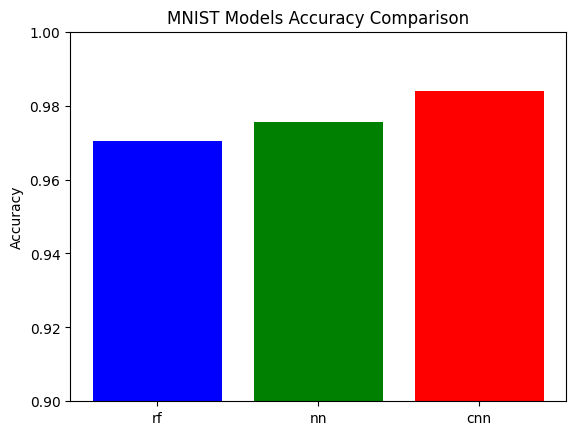

In [6]:
(_, _), (X_test_m, y_test_m) = tf.keras.datasets.mnist.load_data()
X_test_m_proc = X_test_m.reshape((-1, 28, 28, 1)).astype('float32') / 255

algorithms = ['rf', 'nn', 'cnn']
mnist_results = {}

print("--- Evaluating MNIST Models ---")
for alg in algorithms:
    clf = MnistClassifier(alg)

    ext = 'joblib' if alg == 'rf' else 'h5'
    clf.load(f"./Task_1/models/mnist_{alg}.{ext}")
    
    preds = clf.predict(X_test_m_proc)
    acc = accuracy_score(y_test_m, preds)
    mnist_results[alg] = acc
    print(f"Algorithm: {alg.upper():<4} | Test Accuracy: {acc:.4f}")

plt.bar(mnist_results.keys(), mnist_results.values(), color=['blue', 'green', 'red'])
plt.ylim(0.9, 1.0)
plt.title("MNIST Models Accuracy Comparison")
plt.ylabel("Accuracy")
plt.show()

In [7]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

img_model = tf.keras.models.load_model('./Task_2/CV_model/animal_classifier.h5', 
                                       custom_objects={'preprocess_input': preprocess_input})
test_ds = tf.keras.utils.image_dataset_from_directory(
    "./Task_2/CV_model/data/Testing Data/Testing Data",
    image_size=(256, 256),
    batch_size=32
)

_, img_acc = img_model.evaluate(test_ds, verbose=0)

print(f"Image Classifier Accuracy (Test set): {img_acc:.4f}")

Found 2407 files belonging to 15 classes.
Image Classifier Accuracy (Test set): 0.9435


--- Case 1: Match ---


Loading weights: 100%|██████████| 102/102 [00:00<00:00, 6158.42it/s]


Text says: dog | Image shows: dog
Final Result: True

--- Case 2: Mismatch ---


Loading weights: 100%|██████████| 102/102 [00:00<00:00, 5609.27it/s]


Text says: elephant | Image shows: cat
Final Result: False


Loading weights: 100%|██████████| 102/102 [00:00<00:00, 5338.26it/s]


Text says: dog | Image shows: dog


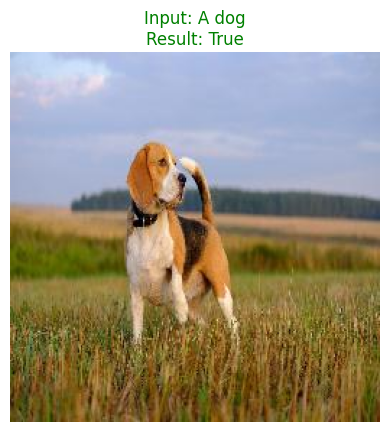


--- Edge Case: No animal in text ---


Loading weights: 100%|██████████| 102/102 [00:00<00:00, 5983.65it/s]

NER: No animal mentioned in text.


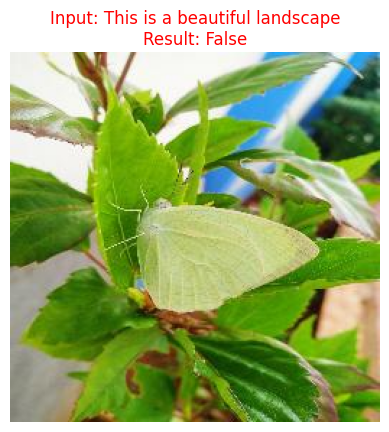


--- Edge Case: Two animals in text ---


Loading weights: 100%|██████████| 102/102 [00:00<00:00, 6355.01it/s]


Text says: monkey | Image shows: monkey


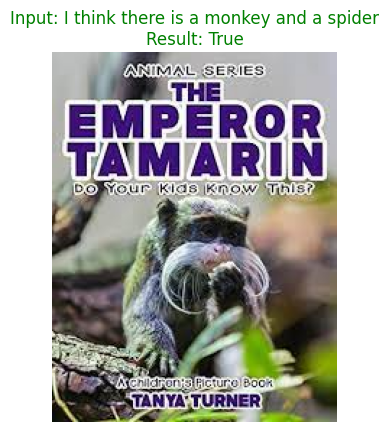


--- Edge Case: Two animals in text in reverse order---


Loading weights: 100%|██████████| 102/102 [00:00<00:00, 4466.03it/s]


Text says: spider | Image shows: monkey
Final Result: False


In [12]:
import sys
import os

task2_path = os.path.abspath("Task_2")
if task2_path not in sys.path:
    sys.path.append(task2_path)

from Task_2.pipeline import run_pipeline

def show_demo_result(text, img_path, res):
    img = Image.open(img_path)
    plt.imshow(img)
    plt.axis('off')
    color = 'green' if res else 'red'
    plt.title(f"Input: {text}\nResult: {res}", color=color)
    plt.show()

NER_MODEL_PATH = "./Task_2/NER_model/animal_ner_model"
IMG_MODEL_PATH = "./Task_2/CV_model/animal_classifier.h5"

print("--- Case 1: Match ---")
result1 = run_pipeline(
    text="A photo of a dog", 
    image_path="./Task_2/CV_model/data/Testing Data/Testing Data/Dog/Dog-test (10).jpg",
    ner_path=NER_MODEL_PATH,
    img_model_path=IMG_MODEL_PATH
)
print(f"Final Result: {result1}")

print("\n--- Case 2: Mismatch ---")
result2 = run_pipeline(
    text="Look at this elephant", 
    image_path="./Task_2/CV_model/data/Testing Data/Testing Data/Cat/cat-test (10).jpeg",
    ner_path=NER_MODEL_PATH,
    img_model_path=IMG_MODEL_PATH
)
print(f"Final Result: {result2}")

res = run_pipeline("A dog", "./Task_2/CV_model/data/Testing Data/Testing Data/Dog/Dog-test (10).jpg", NER_MODEL_PATH, IMG_MODEL_PATH)
show_demo_result("A dog", "./Task_2/CV_model/data/Testing Data/Testing Data/Dog/Dog-test (10).jpg", res)

print("\n--- Edge Case: No animal in text ---")
result3 = run_pipeline(
    text="This is a beautiful landscape", 
    image_path="./Task_2/CV_model/data/Testing Data/Testing Data/Butterfly/butterfly-test (10).jpg",
    ner_path=NER_MODEL_PATH,
    img_model_path=IMG_MODEL_PATH
)
show_demo_result("This is a beautiful landscape", "./Task_2/CV_model/data/Testing Data/Testing Data/Butterfly/butterfly-test (10).jpg", result3)

print("\n--- Edge Case: Two animals in text ---")
result4 = run_pipeline(
    text="I think there is a monkey and a spider", 
    image_path="./Task_2/CV_model/data/Testing Data/Testing Data/Monkey/Monkey (1).jpeg",
    ner_path=NER_MODEL_PATH,
    img_model_path=IMG_MODEL_PATH
)
show_demo_result("I think there is a monkey and a spider", "./Task_2/CV_model/data/Testing Data/Testing Data/Monkey/Monkey (1).jpeg", result4)

print("\n--- Edge Case: Two animals in text in reverse order---")
result5 = run_pipeline(
    text="I think there is a spider and a monkey", 
    image_path="./Task_2/CV_model/data/Testing Data/Testing Data/Monkey/Monkey (1).jpeg",
    ner_path=NER_MODEL_PATH,
    img_model_path=IMG_MODEL_PATH
)
print(f"Final Result: {result5}")